In [ ]:
import pandas as pd

df = pd.read_csv("Rice_C_O.csv")
df.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.578979,229.749878,85.093788,0.928882,15617,0.572896,Cammeo
1,14656,494.311005,206.020065,91.730972,0.895405,15072,0.615436,Cammeo
2,14634,501.122009,214.106781,87.768288,0.912118,14954,0.693259,Cammeo
3,13176,458.342987,193.337387,87.448395,0.891861,13368,0.640669,Cammeo
4,14688,507.166992,211.743378,89.312454,0.906691,15262,0.646024,Cammeo


In [ ]:
print("Rows and columns:", df.shape)  # total numbers of rows and columns
print("\nColumn types:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())    # missing values
print("\nNumber of each rice type:")
print(df["Class"].value_counts())

Rows and columns: (3810, 8)

Column types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   int64  
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   int64  
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(5), int64(2), object(1)
memory usage: 238.3+ KB

Missing values:
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64

Number of each rice type:
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64


In [ ]:
# Input features: all seven rice measurements
X = df.drop(columns=["Class"])

# Target: convert the rice names into numbers
y = df["Class"].map({"Cammeo": 0, "Osmancik": 1})

print("Input features:")
print(X.head())

print("Target:")
print(y.head())

Input features:
    Area   Perimeter  Major_Axis_Length  Minor_Axis_Length  Eccentricity  \
0  15231  525.578979         229.749878          85.093788      0.928882   
1  14656  494.311005         206.020065          91.730972      0.895405   
2  14634  501.122009         214.106781          87.768288      0.912118   
3  13176  458.342987         193.337387          87.448395      0.891861   
4  14688  507.166992         211.743378          89.312454      0.906691   

   Convex_Area    Extent  
0        15617  0.572896  
1        15072  0.615436  
2        14954  0.693259  
3        13368  0.640669  
4        15262  0.646024  
Target:
0    0
1    0
2    0
3    0
4    0
Name: Class, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 3048
Test rows: 762


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42))

print("Logistic Regression pipeline ready")

Logistic Regression pipeline ready


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

logistic_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = logistic_cv[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy: 0.933 ± 0.010
precision: 0.942 ± 0.007
recall: 0.941 ± 0.019
f1: 0.941 ± 0.009
roc_auc: 0.980 ± 0.003


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": [2, 3, 5, None]},
    scoring="f1",
    cv=cv,
    return_train_score=True)

tree_search.fit(X_train, y_train)

tree_results = pd.DataFrame(tree_search.cv_results_)

print(tree_results[
    ["param_max_depth", "mean_train_score",
     "mean_test_score", "std_test_score"]
].round(3))

print("Best depth:", tree_search.best_params_["max_depth"])

tree_model = tree_search.best_estimator_

  param_max_depth  mean_train_score  mean_test_score  std_test_score
0               2             0.941            0.937           0.009
1               3             0.942            0.936           0.007
2               5             0.950            0.929           0.013
3            None             1.000            0.901           0.008
Best depth: 2


In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid={"n_estimators": [50, 100, 200]},
    scoring="f1",
    cv=cv,
    return_train_score=True,
    n_jobs=-1)

forest_search.fit(X_train, y_train)

forest_results = pd.DataFrame(forest_search.cv_results_)

print(forest_results[
    ["param_n_estimators", "mean_train_score",
     "mean_test_score", "std_test_score"]
].round(3))

print("\nBest number of trees:",
      forest_search.best_params_["n_estimators"])

forest_model = forest_search.best_estimator_

   param_n_estimators  mean_train_score  mean_test_score  std_test_score
0                  50             0.999            0.932           0.007
1                 100             1.000            0.932           0.007
2                 200             1.000            0.931           0.008

Best number of trees: 50


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.916,0.915,0.940,0.928,0.975
Decision Tree,0.916,0.913,0.943,0.928,0.950
Random Forest,0.917,0.914,0.945,0.929,0.971


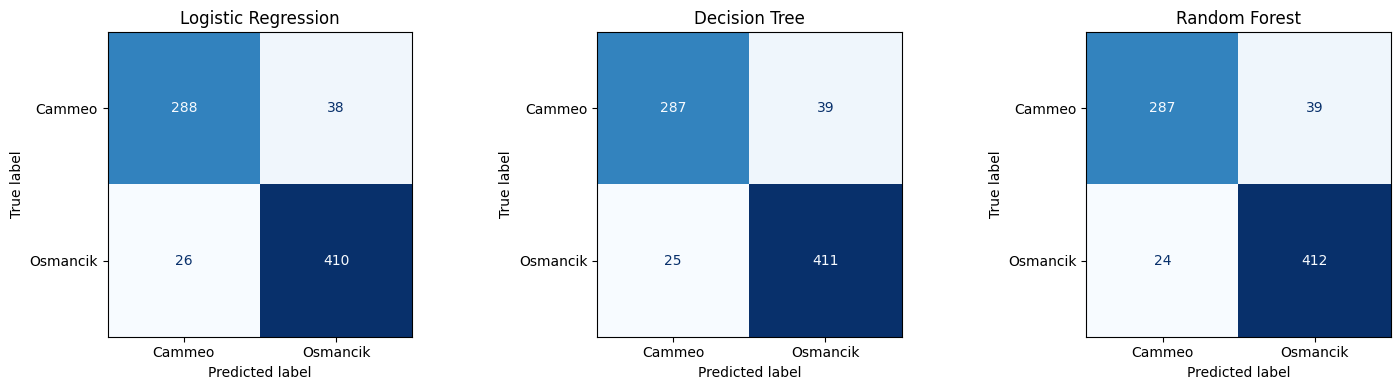

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        labels=[0, 1],
        display_labels=["Cammeo", "Osmancik"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

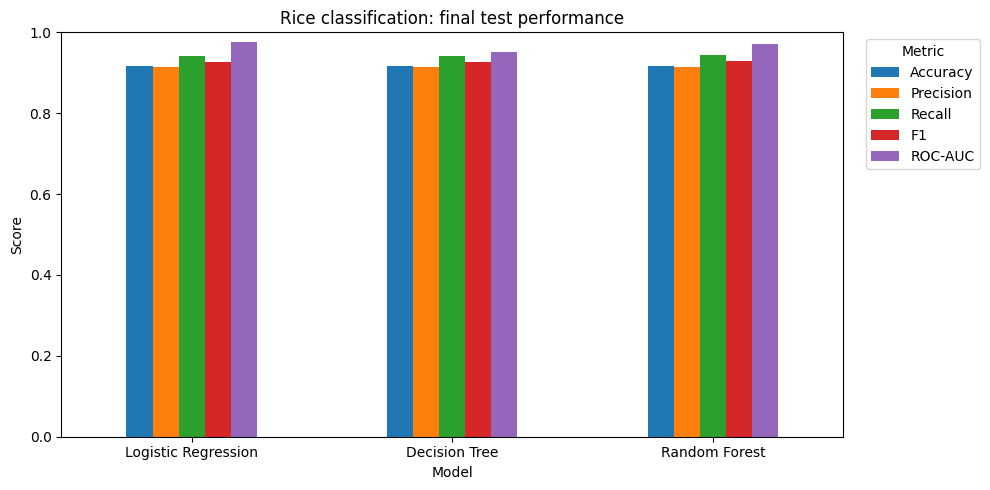

In [ ]:
results_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Rice classification: final test performance")
plt.xlabel("Model")
plt.ylabel("Score")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
# Part B: Steam games

import pandas as pd
games_df = pd.read_csv("steam_games.csv") # Load the dataset
display(games_df.head()) # Preview the data
print("Dataset shape:", games_df.shape) # Check the dataset size

print("Missing values:")
print(games_df.isnull().sum())       # Check for missing values and duplicate rows

print("Duplicate rows:", games_df.duplicated().sum())

,AppID,Name,Release_Date,Primary_Genre,All_Tags,Price_USD,Discount_Pct,Review_Score_Pct,Total_Reviews,Steam_Deck_Status,Estimated_Owners,24h_Peak_Players
0,730,Counter-Strike 2,2012-08-21,Action,FPS;Shooter;Multiplayer;Competitive;Action;Tea...,0.00,0,83,4980365,Unknown,149410950,1013936
1,2868840,Slay the Spire 2,2026-03-05,Indie,Strategy;Roguelike;Card Game;Deckbuilding;Co-o...,24.99,0,97,49549,Unknown,1486470,0
2,3321460,Crimson Desert,2026-03-19,Action,Action;Open World;Singleplayer;Adventure;Comba...,69.99,0,0,0,Unknown,0,0
3,3065800,Marathon,2026-03-05,Action,Extraction Shooter;PvP;Multiplayer;Sci-fi;Shoo...,39.99,0,90,24360,Unknown,730800,0
4,3764200,Resident Evil Requiem,2026-02-26,Action,Survival Horror;Zombies;Horror;Third-Person Sh...,69.99,0,96,79667,Unknown,2390010,0


Dataset shape: (1000, 12)
Missing values:
AppID                 0
Name                  0
Release_Date          1
Primary_Genre         0
All_Tags             14
Price_USD             0
Discount_Pct          0
Review_Score_Pct      0
Total_Reviews         0
Steam_Deck_Status     0
Estimated_Owners      0
24h_Peak_Players      0
dtype: int64
Duplicate rows: 0


In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
games_clean = games_df[games_df["Total_Reviews"] > 0].copy()  # thios will keep games that have a min 1 review

games_features = games_clean[
    ["Price_USD", "Review_Score_Pct", "Total_Reviews"]      # Select meaningful numerical features
].copy()

# Standardise the features before distance-based clustering
games_scaler = StandardScaler()
games_scaled = games_scaler.fit_transform(games_features)

print("Games used for clustering:", len(games_clean))
print("Scaled data shape:", games_scaled.shape)

display(pd.DataFrame(
    games_scaled,
    columns=games_features.columns,
    index=games_features.index
).head())

Games used for clustering: 898
Scaled data shape: (898, 3)


,Price_USD,Review_Score_Pct,Total_Reviews
0,-1.307558,0.027806,22.112622
1,0.077141,1.023735,-0.097189
3,0.908293,0.525770,-0.210648
4,2.570596,0.952597,0.038471
5,0.908293,0.027806,-0.307918


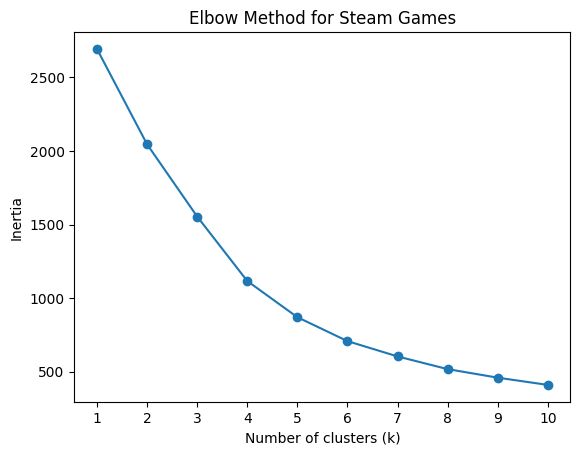

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 1 and 10 clusters
games_k_values = range(1, 11)
games_inertia = []

for k in games_k_values:
    games_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    games_model.fit(games_scaled)
    games_inertia.append(games_model.inertia_)
plt.plot(games_k_values, games_inertia, marker="o")    #elbowgraphh
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Steam Games")
plt.xticks(games_k_values)
plt.show()

Silhouette score: 0.394

Games in each cluster:
KMeans_Cluster
0    152
1      1
2    536
3    209
Name: count, dtype: int64


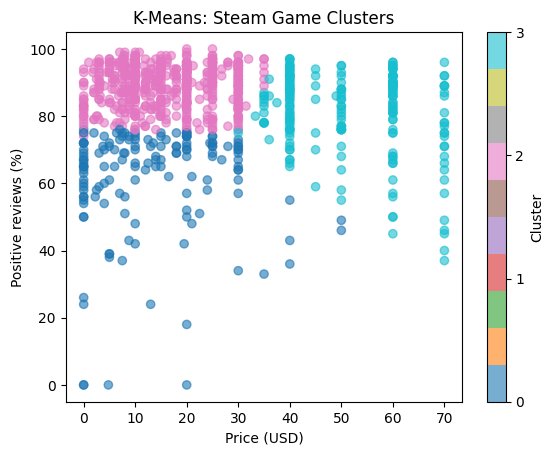

In [ ]:
from sklearn.metrics import silhouette_score

# Groupin the games into 4 clusters
games_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10)

games_clean["KMeans_Cluster"] = games_kmeans.fit_predict(games_scaled)

# Calculated the silhouette score using all three scaled features
games_kmeans_score = silhouette_score(
    games_scaled,
    games_clean["KMeans_Cluster"])

print("Silhouette score:", round(games_kmeans_score, 3))

print("\nGames in each cluster:")
print(games_clean["KMeans_Cluster"].value_counts().sort_index())

# Display the clusters using price and review score
plt.scatter(
    games_clean["Price_USD"],
    games_clean["Review_Score_Pct"],
    c=games_clean["KMeans_Cluster"],
    cmap="tab10",
    alpha=0.6)

plt.xlabel("Price (USD)")
plt.ylabel("Positive reviews (%)")
plt.title("K-Means: Steam Game Clusters")
plt.colorbar(label="Cluster", ticks=[0, 1, 2, 3])
plt.show()

Silhouette score: 0.309

Games in each cluster:
Hierarchical_Cluster
0    245
1    272
2      1
3    380
Name: count, dtype: int64


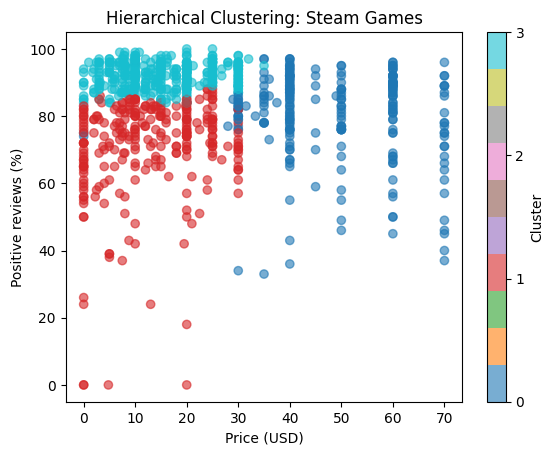

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Build four clusters by progressively merging similar groups
games_hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward")

games_clean["Hierarchical_Cluster"] = (
    games_hierarchical.fit_predict(games_scaled))

games_hierarchical_score = silhouette_score(
    games_scaled,
    games_clean["Hierarchical_Cluster"])        # Calculate the silhouette score

print("Silhouette score:", round(games_hierarchical_score, 3))

print("\nGames in each cluster:")
print(
    games_clean["Hierarchical_Cluster"]
    .value_counts()
    .sort_index())

# Display the clusters
plt.scatter(
    games_clean["Price_USD"],
    games_clean["Review_Score_Pct"],
    c=games_clean["Hierarchical_Cluster"],
    cmap="tab10",
    alpha=0.6)
plt.xlabel("Price (USD)")
plt.ylabel("Positive reviews (%)")
plt.title("Hierarchical Clustering: Steam Games")
plt.colorbar(label="Cluster", ticks=[0, 1, 2, 3])
plt.show()

eps: 0.2
min_samples: 5
Number of clusters: 13
Number of noise points: 257
Silhouette score: 0.155


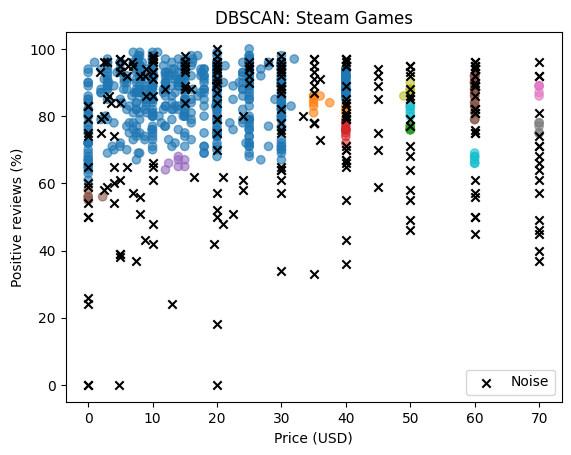

In [ ]:
from sklearn.cluster import DBSCAN

# Start with the settings used in the workshop
games_dbscan = DBSCAN(eps=0.2, min_samples=5)

games_dbscan_labels = games_dbscan.fit_predict(games_scaled)
games_clean["DBSCAN_Cluster"] = games_dbscan_labels

games_cluster_count = len(set(games_dbscan_labels) - {-1})
games_noise_count = (games_dbscan_labels == -1).sum()

print("eps:", games_dbscan.eps)
print("min_samples:", games_dbscan.min_samples)
print("Number of clusters:", games_cluster_count)
print("Number of noise points:", games_noise_count)

games_not_noise = games_dbscan_labels != -1  # Exclude noise when calculating the silhouette score
games_dbscan_score = float("nan")

if 2 <= games_cluster_count < games_not_noise.sum():
    games_dbscan_score = silhouette_score(
        games_scaled[games_not_noise],
        games_dbscan_labels[games_not_noise])
    print("Silhouette score:", round(games_dbscan_score, 3))
else:
    print("Silhouette score cannot be calculated for this result.")

# Plot clustered games
plt.scatter(
    games_clean.loc[games_not_noise, "Price_USD"],
    games_clean.loc[games_not_noise, "Review_Score_Pct"],
    c=games_dbscan_labels[games_not_noise],
    cmap="tab10",
    alpha=0.6)

# Show noise separately as black crosses
plt.scatter(
    games_clean.loc[~games_not_noise, "Price_USD"],
    games_clean.loc[~games_not_noise, "Review_Score_Pct"],
    color="black",
    marker="x",
    label="Noise")

plt.xlabel("Price (USD)")
plt.ylabel("Positive reviews (%)")
plt.title("DBSCAN: Steam Games")
plt.legend()
plt.show()

eps: 0.3
min_samples: 5
Number of clusters: 8
Number of noise points: 126
Silhouette score: 0.334


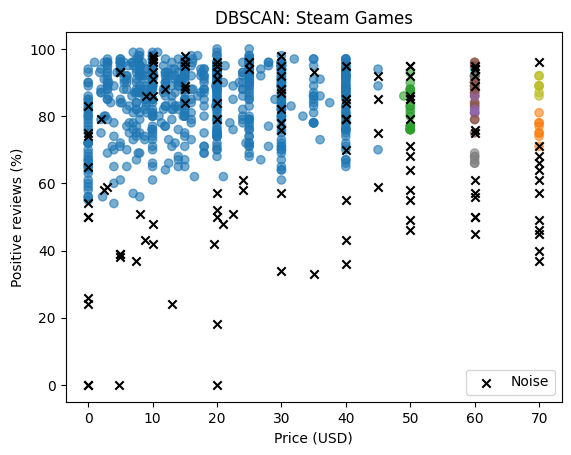

In [ ]:
from sklearn.cluster import DBSCAN

# Start with the settings used in the workshop
games_dbscan = DBSCAN(eps=0.3, min_samples=5)   #

games_dbscan_labels = games_dbscan.fit_predict(games_scaled)
games_clean["DBSCAN_Cluster"] = games_dbscan_labels

games_cluster_count = len(set(games_dbscan_labels) - {-1})
games_noise_count = (games_dbscan_labels == -1).sum()

print("eps:", games_dbscan.eps)
print("min_samples:", games_dbscan.min_samples)
print("Number of clusters:", games_cluster_count)
print("Number of noise points:", games_noise_count)

games_not_noise = games_dbscan_labels != -1  # Exclude noise when calculating the silhouette score
games_dbscan_score = float("nan")

if 2 <= games_cluster_count < games_not_noise.sum():
    games_dbscan_score = silhouette_score(
        games_scaled[games_not_noise],
        games_dbscan_labels[games_not_noise])
    print("Silhouette score:", round(games_dbscan_score, 3))
else:
    print("Silhouette score cannot be calculated for this result.")

# Plot clustered games
plt.scatter(
    games_clean.loc[games_not_noise, "Price_USD"],
    games_clean.loc[games_not_noise, "Review_Score_Pct"],
    c=games_dbscan_labels[games_not_noise],
    cmap="tab10",
    alpha=0.6)

# Show noise separately as black crosses
plt.scatter(
    games_clean.loc[~games_not_noise, "Price_USD"],
    games_clean.loc[~games_not_noise, "Review_Score_Pct"],
    color="black",
    marker="x",
    label="Noise")

plt.xlabel("Price (USD)")
plt.ylabel("Positive reviews (%)")
plt.title("DBSCAN: Steam Games")
plt.legend()
plt.show()

In [ ]:
# Comparing the three clustering methods
games_comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical",
        "DBSCAN"
    ],
    "Clusters": [
        4,
        4,
        games_cluster_count ],
    "Noise points": [
        0,
        0,
        games_noise_count
    ],
    "Silhouette score": [
        games_kmeans_score,
        games_hierarchical_score,
        games_dbscan_score
    ],
    "Games scored": [
        len(games_clean),
        len(games_clean),
        int(games_not_noise.sum())
    ]})

display(games_comparison.round(3))

,Algorithm,Clusters,Noise points,Silhouette score,Games scored
0,K-Means,4,0,0.394,898
1,Hierarchical,4,0,0.309,898
2,DBSCAN,8,126,0.334,772


In [ ]:
# this sshows the average measurements for each K-Means cluster
display(
    games_clean.groupby("KMeans_Cluster")[
        ["Price_USD", "Review_Score_Pct", "Total_Reviews"]
    ].mean().round(2)
)

#this identify the game in the one-game cluster
display(
    games_clean.loc[
        games_clean["KMeans_Cluster"] == 1,
        ["Name", "Price_USD", "Review_Score_Pct", "Total_Reviews"]
    ]
)

,Price_USD,Review_Score_Pct,Total_Reviews
KMeans_Cluster,,,
0,13.47,61.62,23506.12
1,0.00,83.00,4980365.00
2,15.89,89.13,67754.78
3,50.84,81.16,90915.47


,Name,Price_USD,Review_Score_Pct,Total_Reviews
0,Counter-Strike 2,0.0,83,4980365


In [70]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# excluded Counter-Strike 2 for this additional comparison
games_without_cs2 = games_clean[
    games_clean["Name"] != "Counter-Strike 2"
].copy()

#keep the same three features
comparison_features = games_without_cs2[
    ["Price_USD", "Review_Score_Pct", "Total_Reviews"]]

# fited a new scaler to the remaining games
comparison_scaled = StandardScaler().fit_transform(
    comparison_features)

# I keep four clusters and the same K-Means settings
comparison_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10)

comparison_labels = comparison_kmeans.fit_predict(
    comparison_scaled)

#check cluster sizes and separation
print("Games included:", len(games_without_cs2))

print("\nGames in each cluster:")
print(pd.Series(comparison_labels).value_counts().sort_index())

print("\nSilhouette score:", round(
    silhouette_score(comparison_scaled, comparison_labels), 3))

Games included: 897

Games in each cluster:
0    145
1    200
2     24
3    528
Name: count, dtype: int64

Silhouette score: 0.401


In [71]:
# I compare three and four clusters without Counter-Strike 2
for k in [3, 4]:
    check_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    check_labels = check_model.fit_predict(comparison_scaled)

    print("\nNumber of clusters:", k)
    print("Cluster sizes:")
    print(pd.Series(check_labels).value_counts().sort_index())

    print("Silhouette score:", round(
        silhouette_score(comparison_scaled, check_labels), 3
    ))


Number of clusters: 3
Cluster sizes:
0     24
1    226
2    647
Name: count, dtype: int64
Silhouette score: 0.394

Number of clusters: 4
Cluster sizes:
0    145
1    200
2     24
3    528
Name: count, dtype: int64
Silhouette score: 0.401


In [ ]:
#task2 Neural networks
import numpy as np
from sklearn.preprocessing import StandardScaler

nn_scaler = StandardScaler()  # Scale the rice data using the same split from Task 1A
X_train_nn = nn_scaler.fit_transform(X_train) # Learn the scaling values from the training data only
X_test_nn = nn_scaler.transform(X_test) # Apply the same scaling to the test data

print("Training data shape:", X_train_nn.shape)
print("Test data shape:", X_test_nn.shape)

Training data shape: (3048, 7)
Test data shape: (762, 7)


In [ ]:
# Make the random weights repeatable
np.random.seed(42)
#Seven inputs four hidden neurons and one output
input_size = X_train_nn.shape[1]
hidden_size = 4
output_size = 1

           #Hidden layer weights and biases
W1 = np.random.randn(input_size, hidden_size) * 0.1
b1 = np.zeros((1, hidden_size))

            #Output layer weights and bias
W2 = np.random.randn(hidden_size, output_size) * 0.1
b2 = np.zeros((1, output_size))
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (7, 4)
b1 shape: (1, 4)
W2 shape: (4, 1)
b2 shape: (1, 1)


In [ ]:
def relu(z):    #ReLU, it keeps the value positive, so negative will be 0
    return np.maximum(0, z)

def sigmoid(z):           #Sigmoid converts values into probabilities between 0 and 1
    return 1 / (1 + np.exp(-z))

#Calculate the hidden layer values
z1 = X_test_nn @ W1 + b1
a1 = relu(z1)

#Calculate the output probabilities
z2 = a1 @ W2 + b2     #matrix multiplication
nn_probabilities = sigmoid(z2)

#Use 0.5 as the threshold for predicting the rice variety
nn_predictions = (nn_probabilities >= 0.5).astype(int)

print("First five probabilities:")
print(nn_probabilities[:5])

print("First five predictions:")
print(nn_predictions[:5])

print("Output shape:", nn_probabilities.shape)

First five probabilities:
[[0.49616271]
 [0.49621719]
 [0.49828578]
 [0.49290277]
 [0.49509203]]
First five predictions:
[[0]
 [0]
 [0]
 [0]
 [0]]
Output shape: (762, 1)


In [ ]:
# Get the actual label and probability for the first test grain
actual_label = y_test.iloc[0]
predicted_probability = nn_probabilities[0, 0]

# Avoid taking the logarithm of zero
p = np.clip(predicted_probability, 1e-10, 1 - 1e-10)

# Calculate binary cross-entropy loss
loss = -(actual_label * np.log(p)
         + (1 - actual_label) * np.log(1 - p))

print("Actual label:", actual_label)
print("Predicted probability:", round(predicted_probability, 6))
print("Predicted label:", nn_predictions[0, 0])
print("Binary cross-entropy loss:", round(loss, 6))

Actual label: 0
Predicted probability: 0.496163
Predicted label: 0
Binary cross-entropy loss: 0.685502


In [ ]:
actual_label = y_test.iloc[0]
predicted_probability = nn_probabilities[0, 0]

p = np.clip(predicted_probability, 1e-10, 1 - 1e-10)

loss = -(actual_label * np.log(p)
         + (1 - actual_label) * np.log(1 - p))

print("Actual label:", actual_label)
print("Predicted probability:", round(predicted_probability, 6))
print("Predicted label:", nn_predictions[0, 0])
print("Binary cross-entropy loss:", round(loss, 6))

Actual label: 0
Predicted probability: 0.496163
Predicted label: 0
Binary cross-entropy loss: 0.685502


In [ ]:
#selected the first test grain for my worked example
sample = X_test_nn[0]
#displaying its scaled measurements in their original feature order
print("Feature names:", list(X_train.columns))
print("Scaled input values:", np.round(sample, 6))
#I also have display the seven weights and bias for the first hidden neuron
print("First hidden neuron weights:", np.round(W1[:, 0], 6))
print("First hidden neuron bias:", b1[0, 0])

#I have display the weighted sum and activation calculated by the network
print("First neuron weighted sum:", round(z1[0, 0], 6))
print("First neuron ReLU result:", round(a1[0, 0], 6))

#all four hidden activations and the output layer values
print("Full hidden activation vector:", np.round(a1[0], 6))
print("Output weights:", np.round(W2[:, 0], 6))
print("Output bias:", b2[0, 0])
print("Output weighted sum:", round(z2[0, 0], 6))
print("Output probability:", round(nn_probabilities[0, 0], 6))

Feature names: ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
Scaled input values: [ 1.143617  1.118839  0.985382  0.933818  0.420388  1.187491 -0.608305]
First hidden neuron weights: [ 0.049671 -0.023415 -0.046947  0.024196 -0.101283  0.146565 -0.054438]
First hidden neuron bias: 0.0
First neuron weighted sum: 0.171522
First neuron ReLU result: 0.171522
Full hidden activation vector: [0.171522 0.       0.083881 0.      ]
Output weights: [-0.060064 -0.029169 -0.060171  0.185228]
Output bias: 0.0
Output weighted sum: -0.015349
Output probability: 0.496163


In [ ]:
#task 2 part B: kera NN
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#I split my original training data into training and validation sets
X_train_keras, X_val_keras, y_train_keras, y_val_keras = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train)
#I learn the scaling values from the training observations only
keras_scaler = StandardScaler()
X_train_keras = keras_scaler.fit_transform(X_train_keras)
#I apply the same scaling to the validation observations
X_val_keras = keras_scaler.transform(X_val_keras)
#I check the number of observations and features
print("Training shape:", X_train_keras.shape)
print("Validation shape:", X_val_keras.shape)

Training shape: (2438, 7)
Validation shape: (610, 7)


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

tf.keras.utils.set_random_seed(42)  # set the random seed to make my experiment repeatable

                       #build a network with seven inputs and four hidden neurons
keras_model_1 = Sequential([
    Input(shape=(7,)),
    Dense(4, activation="relu"),
    Dense(1, activation="sigmoid")])

# choose Adam to update the weights and binary cross-entropy for the loss
keras_model_1.compile(
    optimizer="adam",
    loss="binary_crossentropy",      #adam optimiser algorthm
    metrics=["accuracy"])

#train my network and check its performance on the validation data
history_1 = keras_model_1.fit(
    X_train_keras,
    y_train_keras,
    validation_data=(X_val_keras, y_val_keras),
    epochs=50,
    batch_size=32,
    verbose=1)

Epoch 1/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6440 - loss: 0.5447 - val_accuracy: 0.8049 - val_loss: 0.4976
Epoch 2/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8400 - loss: 0.4374 - val_accuracy: 0.8426 - val_loss: 0.4114
Epoch 3/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8811 - loss: 0.3627 - val_accuracy: 0.8869 - val_loss: 0.3430
Epoch 4/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9020 - loss: 0.3039 - val_accuracy: 0.9115 - val_loss: 0.2889
Epoch 5/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9130 - loss: 0.2620 - val_accuracy: 0.9213 - val_loss: 0.2509
Epoch 6/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9188 - loss: 0.2343 - val_accuracy: 0.9230 - val_loss: 0.2259
Epoch 7/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9249 - loss: 0.2170 - val_accuracy: 0.9230 - val_loss: 0.2096
Epoch 8/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9270 - loss: 0.2060 - val_accuracy: 0.9230 - val_loss:

In [ ]:
tf.keras.utils.set_random_seed(42) #using same seed

#increased the hidden layer from four to eight neurons
keras_model_2 = Sequential([
    Input(shape=(7,)),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")])

#keep the optimiser the loss and accuracy metric the same
keras_model_2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"])

#I will keep the same data, number of epochs and batch size
history_2 = keras_model_2.fit(
    X_train_keras,
    y_train_keras,
    validation_data=(X_val_keras, y_val_keras),
    epochs=50,
    batch_size=32,
    verbose=1)

Epoch 1/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6792 - loss: 0.5113 - val_accuracy: 0.7885 - val_loss: 0.4316
Epoch 2/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8462 - loss: 0.3687 - val_accuracy: 0.8934 - val_loss: 0.3238
Epoch 3/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9159 - loss: 0.2803 - val_accuracy: 0.9246 - val_loss: 0.2481
Epoch 4/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9258 - loss: 0.2287 - val_accuracy: 0.9262 - val_loss: 0.2107
Epoch 5/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9266 - loss: 0.2052 - val_accuracy: 0.9262 - val_loss: 0.1942
Epoch 6/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9270 - loss: 0.1947 - val_accuracy: 0.9295 - val_loss: 0.1868
Epoch 7/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9278 - loss: 0.1895 - val_accuracy: 0.9311 - val_loss: 0.1832
Epoch 8/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9286 - loss: 0.1867 - val_accuracy: 0.9311 - val_loss:

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
tf.keras.utils.set_random_seed(42) #sameseed
#same
keras_model_3 = Sequential([
    Input(shape=(7,)),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")])
#adam
keras_model_3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"])
#stop if validation loss does not improve for five epochs
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True)
#train for up to 50 epochs with Early Stopping
history_3 = keras_model_3.fit(
    X_train_keras,
    y_train_keras,
    validation_data=(X_val_keras, y_val_keras),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1)

print("Epochs completed:", len(history_3.history["loss"]))

Epoch 1/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6792 - loss: 0.5113 - val_accuracy: 0.7885 - val_loss: 0.4316
Epoch 2/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8462 - loss: 0.3687 - val_accuracy: 0.8934 - val_loss: 0.3238
Epoch 3/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9159 - loss: 0.2803 - val_accuracy: 0.9246 - val_loss: 0.2481
Epoch 4/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9258 - loss: 0.2287 - val_accuracy: 0.9262 - val_loss: 0.2107
Epoch 5/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9266 - loss: 0.2052 - val_accuracy: 0.9262 - val_loss: 0.1942
Epoch 6/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9270 - loss: 0.1947 - val_accuracy: 0.9295 - val_loss: 0.1868
Epoch 7/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9278 - loss: 0.1895 - val_accuracy: 0.9311 - val_loss: 0.1832
Epoch 8/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9286 - loss: 0.1867 - val_accuracy: 0.9311 - val_loss

In [ ]:
import pandas as pd

# I check each trained model using the same validation data
val_loss_1, val_acc_1 = keras_model_1.evaluate(
    X_val_keras, y_val_keras, verbose=0)

val_loss_2, val_acc_2 = keras_model_2.evaluate(
    X_val_keras, y_val_keras, verbose=0)

val_loss_3, val_acc_3 = keras_model_3.evaluate(
    X_val_keras, y_val_keras, verbose=0)

#I put the settings and validation results into a comparison table
keras_comparison = pd.DataFrame({
    "Experiment": [1, 2, 3],
    "Hidden neurons": [4, 8, 8],
    "Activation": ["ReLU", "ReLU", "ReLU"],
    "Batch size": [32, 32, 32],
    "Early Stopping": ["No", "No", "Yes"],
    "Epochs completed": [
        len(history_1.history["loss"]),
        len(history_2.history["loss"]),
        len(history_3.history["loss"])],
    "Validation loss": [val_loss_1, val_loss_2, val_loss_3],
    "Validation accuracy": [val_acc_1, val_acc_2, val_acc_3]})

display(keras_comparison.round(4))

,Experiment,Hidden neurons,Activation,Batch size,Early Stopping,Epochs completed,Validation loss,Validation accuracy
0,1,4,ReLU,32,No,50,0.1789,0.9311
1,2,8,ReLU,32,No,50,0.1775,0.9295
2,3,8,ReLU,32,Yes,50,0.1775,0.9295


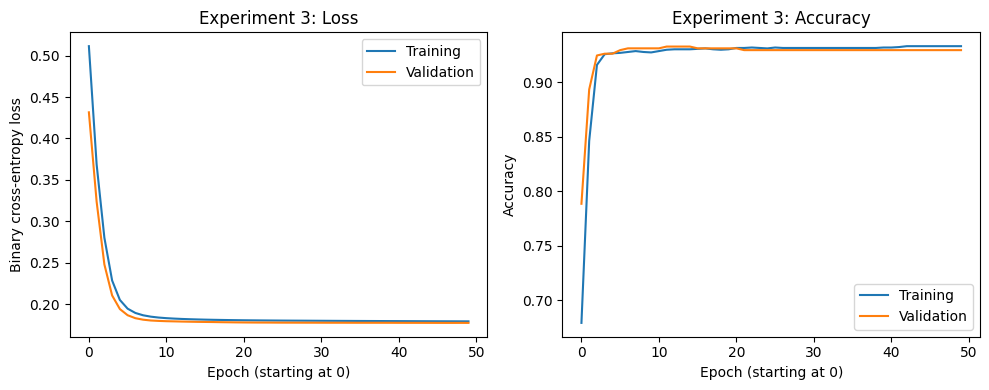

In [ ]:
import matplotlib.pyplot as plt

#selected experimentusing its validation loss
final_keras_model = keras_model_3
final_history = history_3

# plottin training and validation loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(final_history.history["loss"], label="Training")
plt.plot(final_history.history["val_loss"], label="Validation")
plt.xlabel("Epoch (starting at 0)")
plt.ylabel("Binary cross-entropy loss")
plt.title("Experiment 3: Loss")
plt.legend()

# plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(final_history.history["accuracy"], label="Training")
plt.plot(final_history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch (starting at 0)")
plt.ylabel("Accuracy")
plt.title("Experiment 3: Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.916,0.9189,0.9358,0.9273,0.9753


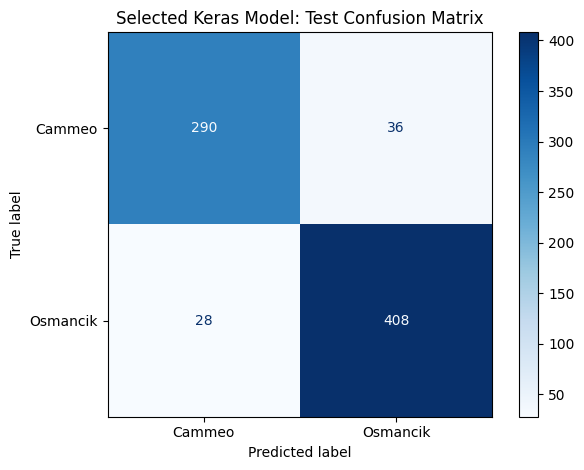

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, ConfusionMatrixDisplay)
X_test_keras = keras_scaler.transform(X_test)  #scaled th test data using my fitted training scaler

#calculate probabilities and convert them into class predictions
keras_test_probabilities = final_keras_model.predict(
    X_test_keras, verbose=0
).ravel()

keras_test_predictions = (
    keras_test_probabilities >= 0.5
).astype(int)

# I report the final test results
keras_test_results = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, keras_test_predictions)],
    "Precision": [precision_score(y_test, keras_test_predictions)],
    "Recall": [recall_score(y_test, keras_test_predictions)],
    "F1": [f1_score(y_test, keras_test_predictions)],
    "ROC-AUC": [roc_auc_score(y_test, keras_test_probabilities)]})

display(keras_test_results.round(4))
#displayed the correct predictions and classification errors
ConfusionMatrixDisplay.from_predictions(
    y_test,
    keras_test_predictions,
    labels=[0, 1],
    display_labels=["Cammeo", "Osmancik"],
    cmap="Blues")

plt.title("Selected Keras Model: Test Confusion Matrix")
plt.tight_layout()
plt.show()